# Real Estate Housing Price Prediction

## Project Overview

This project aims to predict median house values using the California Housing dataset and supervised machine learning regression algorithms.

The project implements Ordinary Least Squares (OLS), Ridge Regression, and Lasso Regression to compare their predictive performance.

## Objectives

- Perform data cleaning and preprocessing.
- Handle missing values.
- Conduct Exploratory Data Analysis (EDA).
- Engineer interaction features.
- Analyze correlation and multicollinearity.
- Apply feature encoding and standardization.
- Train OLS, Ridge, and Lasso regression models.
- Perform hyperparameter tuning using GridSearchCV.
- Evaluate models using RMSE, MAE, and R².
- Analyze residual errors and compare actual vs predicted values.

In [1]:
import pandas as pd 
import numpy as np 
from matplotlib import pyplot as plt 
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import Ridge,Lasso

In [2]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
df.shape

(20640, 10)

In [5]:
df['ocean_proximity'].unique()

array(['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)

In [6]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [7]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].mode()[0])

In [10]:
numeric_df = df.select_dtypes(include='number')
cols = numeric_df.columns

In [11]:
df[cols].describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,535.284351,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,420.053240,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,292.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,431.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


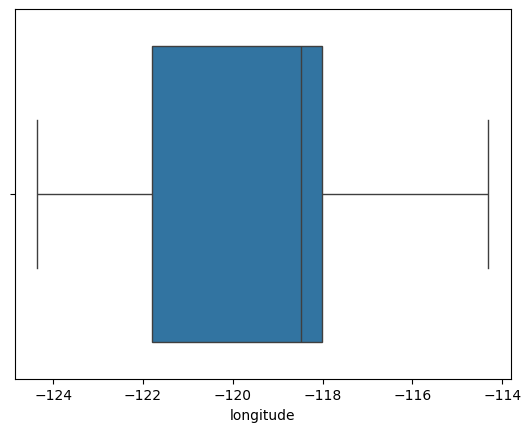

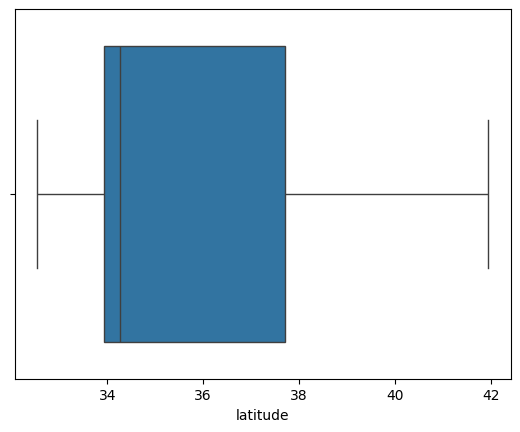

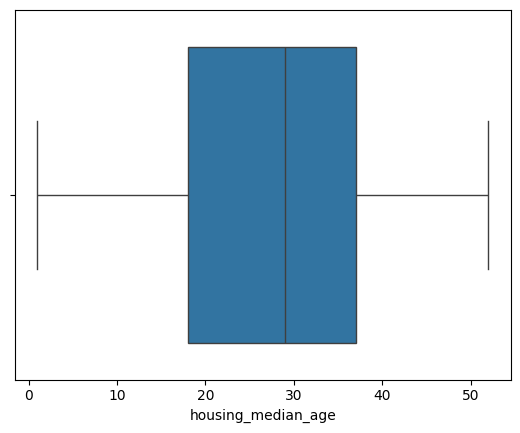

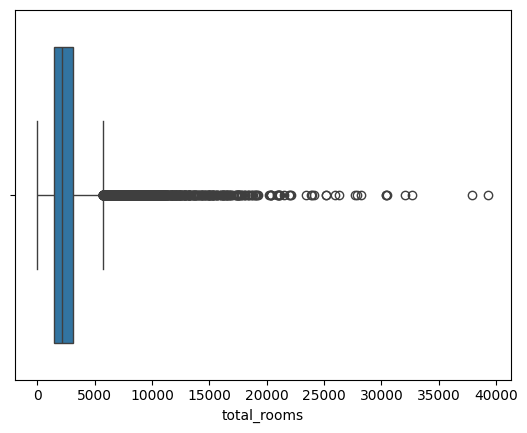

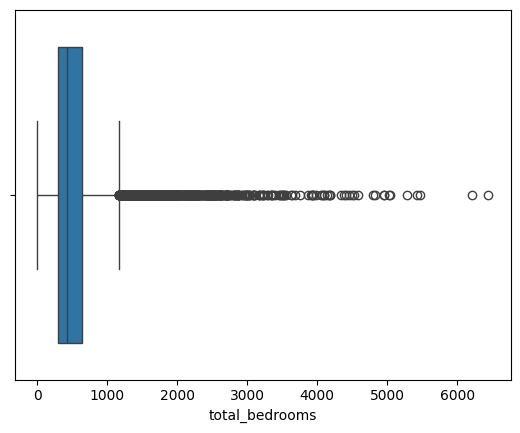

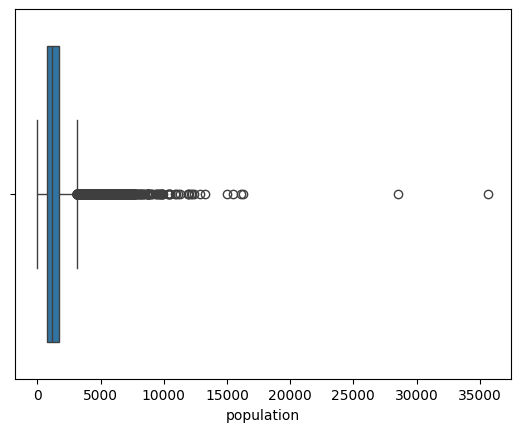

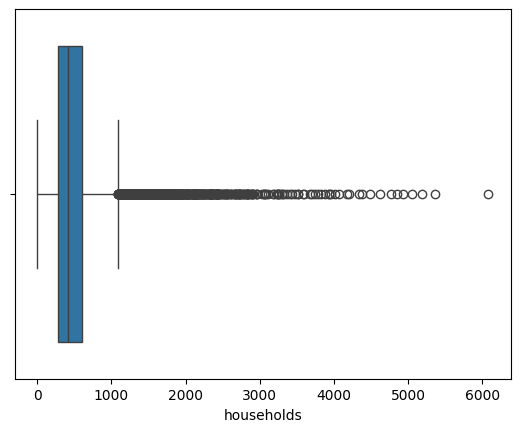

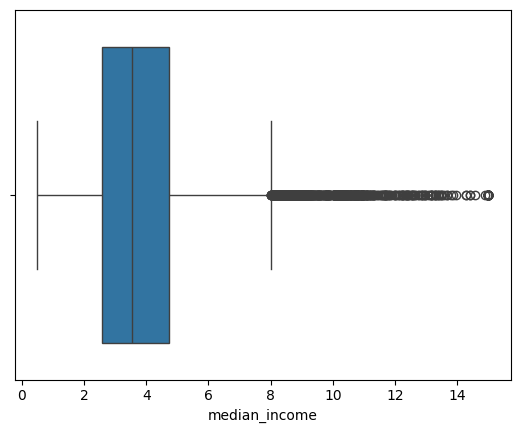

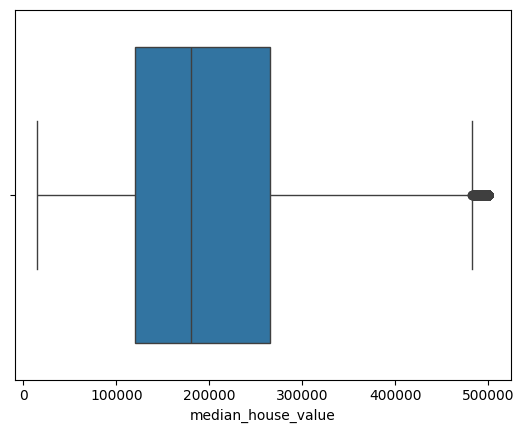

In [12]:
for col in df[cols]:
    sns.boxplot(data = df,x=col)
    plt.show()

In [13]:
q1 = df['total_rooms'].quantile(0.25)
q3 = df['total_rooms'].quantile(0.75)
iqr = q3 - q1
ul = q3 + (iqr * 1.5)
df['total_rooms'] = df['total_rooms'].clip(upper=ul)

In [14]:
Q1 = df['total_bedrooms'].quantile(0.25)
Q3 = df['total_bedrooms'].quantile(0.75)
Iqr = Q3 - Q1
Ul = Q3 + (Iqr * 1.5)
df['total_bedrooms'] = df['total_bedrooms'].clip(upper=Ul)

In [15]:
df.colum = ['population','households','median_income']
for col in df.colum:
    q_1 = df[col].quantile(0.25)
    q_3 = df[col].quantile(0.75)
    IQR =  q_3 - q_1
    UL = q_3 + (IQR*1.5)
    df[col] = df[col].clip(upper=UL)

C:\Users\ZEYAN KHAN\AppData\Local\Temp\ipykernel_5000\1914739803.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.colum = ['population','households','median_income']


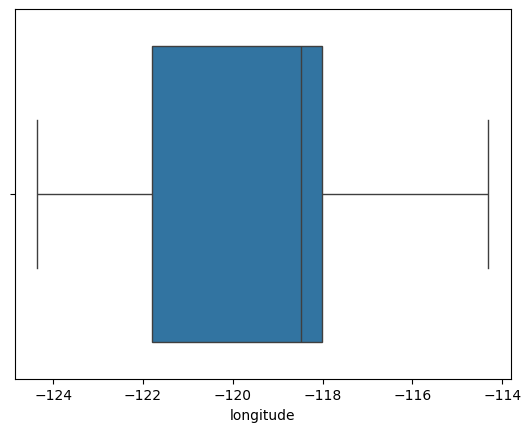

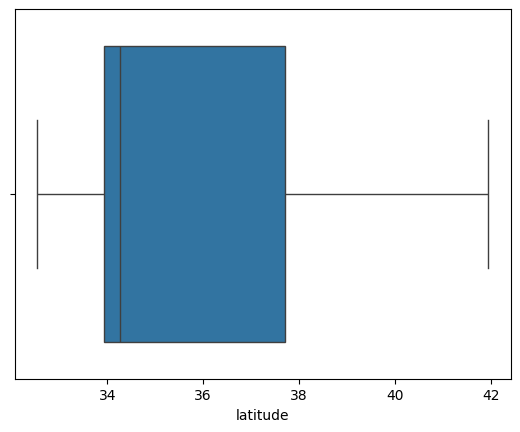

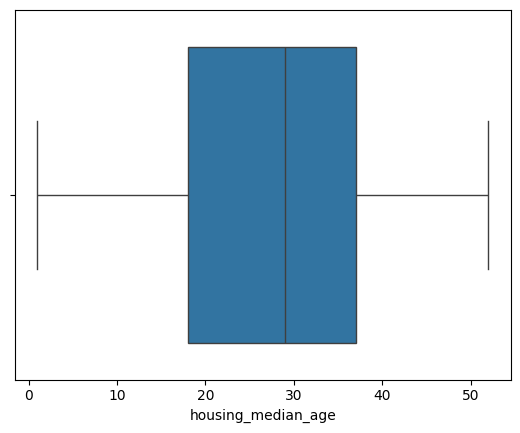

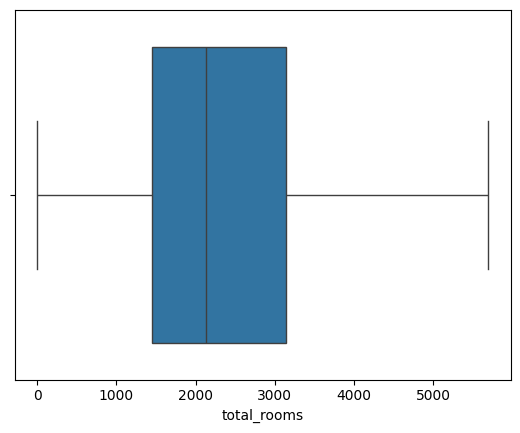

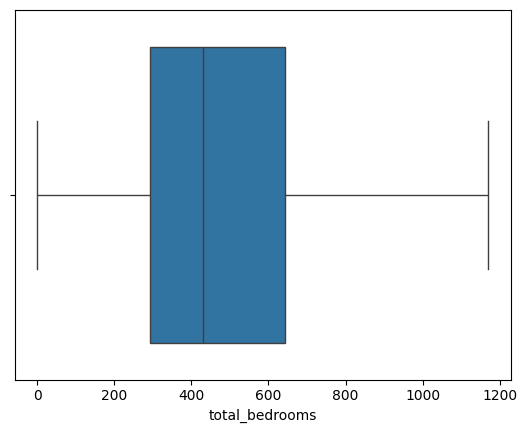

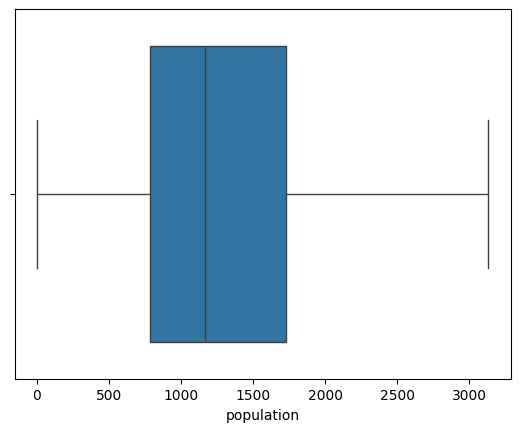

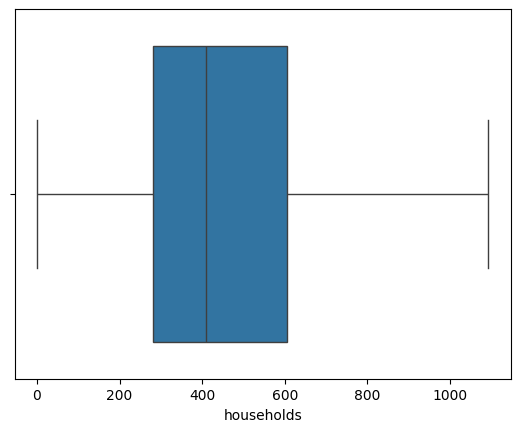

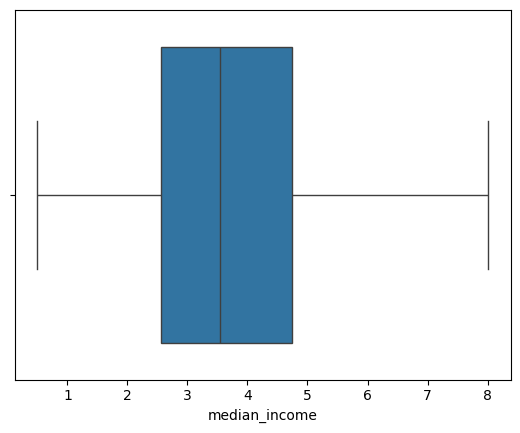

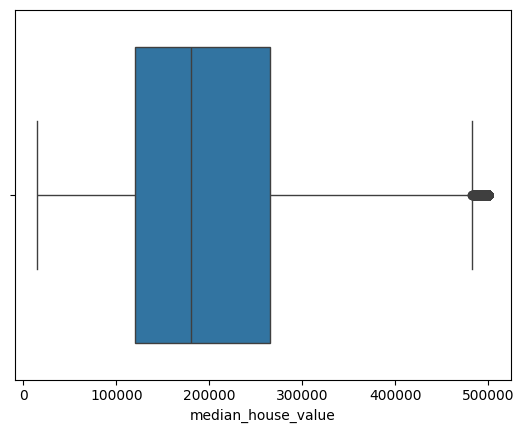

In [16]:
for col in df[cols]:
    sns.boxplot(data = df,x=col)
    plt.show()

## Correlation Heatmap Analysis

Correlation analysis is used to understand the relationship between numerical features in the dataset.

A correlation heatmap visually represents the strength and direction of relationships between variables. It helps identify highly correlated features and potential multicollinearity.

The analysis also helps understand how numerical features are related to the target variable, `median_house_value`.

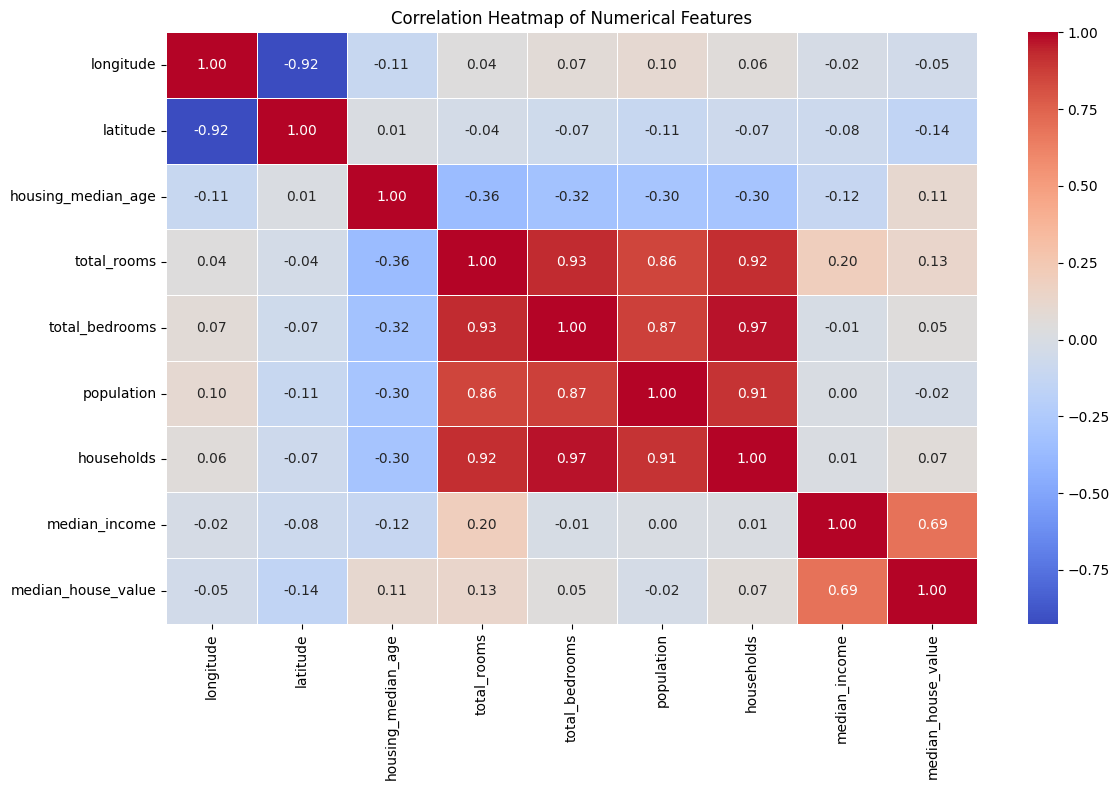

In [17]:
# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

## Feature Engineering: Interaction Features

Feature engineering is the process of creating new features from existing variables to improve model performance.

In this step, interaction features are created by combining relevant numerical variables. These features help capture relationships between different housing attributes that may influence median house values.

In [18]:
df['rooms_per_household'] = (df['total_rooms'] / df['households'])

In [19]:
df['bedrooms_per_room'] = (df['total_bedrooms'] / df['total_rooms'])

In [20]:
df['population_per_household'] = (df['population'] / df['households'])

In [21]:
df[['rooms_per_household','bedrooms_per_room','population_per_household']].head()

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,5.215904,0.194090,2.197712
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467


In [22]:
df['ocean_proximity'].unique()

array(['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)

In [23]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore',drop='first')
encoded_data = encoder.fit_transform(df[['ocean_proximity']])

In [24]:
# Convert encoded data into a DataFrame
encoded_df = pd.DataFrame(encoded_data,columns=encoder.get_feature_names_out(['ocean_proximity']),index=df.index)
df = pd.concat([df.drop('ocean_proximity', axis=1), encoded_df], axis=1)

In [25]:
df['ocean_proximity_INLAND'] = df['ocean_proximity_INLAND'].astype(int)

In [26]:
df['ocean_proximity_ISLAND'] = df['ocean_proximity_ISLAND'].astype(int)

In [27]:
df['ocean_proximity_NEAR BAY'] = df['ocean_proximity_NEAR BAY'].astype(int)

In [28]:
df['ocean_proximity_NEAR OCEAN'] = df['ocean_proximity_NEAR OCEAN'].astype(int)

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   20640 non-null  float64
 1   latitude                    20640 non-null  float64
 2   housing_median_age          20640 non-null  float64
 3   total_rooms                 20640 non-null  float64
 4   total_bedrooms              20640 non-null  float64
 5   population                  20640 non-null  float64
 6   households                  20640 non-null  float64
 7   median_income               20640 non-null  float64
 8   median_house_value          20640 non-null  float64
 9   rooms_per_household         20640 non-null  float64
 10  bedrooms_per_room           20640 non-null  float64
 11  population_per_household    20640 non-null  float64
 12  ocean_proximity_INLAND      20640 non-null  int64  
 13  ocean_proximity_ISLAND      206

## Multicollinearity Analysis using VIF

Variance Inflation Factor (VIF) is used to identify multicollinearity among independent variables. A high VIF value indicates that a feature is highly correlated with other features.

Before calculating VIF, missing and infinite values are checked to ensure accurate results.

In [30]:
# Select numerical independent features
X_vif = df.drop(columns=['median_house_value'])

# Check missing values
print("Missing values:")
print(X_vif.isnull().sum()[X_vif.isnull().sum() > 0])

# Check infinite values
print("\nTotal infinite values:")
print(np.isinf(X_vif.select_dtypes(include=np.number)).sum().sum())

Missing values:
Series([], dtype: int64)

Total infinite values:
0


In [31]:
# Calculate VIF for each independent feature
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Sort VIF values in descending order
vif_data = vif_data.sort_values(by="VIF", ascending=False)

vif_data

,Feature,VIF
6,households,33.078515
4,total_bedrooms,31.507528
3,total_rooms,21.057178
1,latitude,20.684153
0,longitude,18.539034
5,population,6.436289
9,bedrooms_per_room,3.046458
11,ocean_proximity_INLAND,2.898878
7,median_income,2.312218
8,rooms_per_household,1.740574


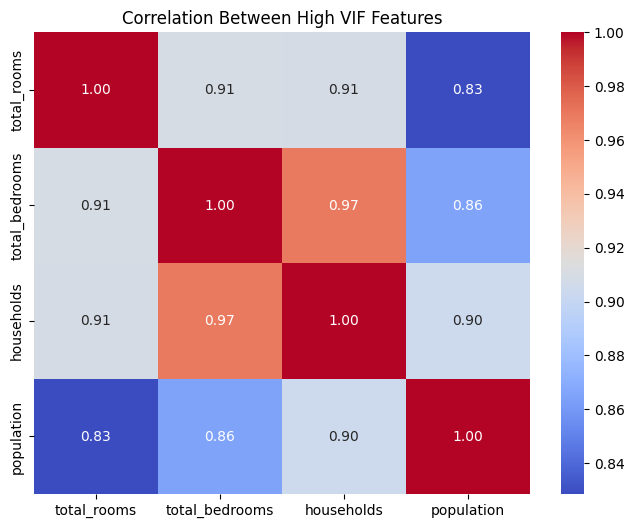

In [32]:
correlation_features = [
    'total_rooms',
    'total_bedrooms',
    'households',
    'population'
]

plt.figure(figsize=(8, 6))

sns.heatmap(df[correlation_features].corr(),annot=True,cmap='coolwarm',fmt='.2f')

plt.title('Correlation Between High VIF Features')
plt.show()

### Handling Multicollinearity

The VIF analysis identified high multicollinearity among certain housing-related numerical features, particularly total_rooms, total_bedrooms, and households.

To investigate these relationships further, a correlation analysis is performed. Features will be selected carefully to reduce redundancy while preserving important predictive information.

In [33]:
# Remove highly correlated feature
df = df.drop(columns=['total_bedrooms'])

print("Updated Dataset Shape:", df.shape)

Updated Dataset Shape: (20640, 15)


In [34]:
X_vif = df.drop(columns=['median_house_value'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_vif)

X_scaled = sm.add_constant(X_scaled)

vif_data = pd.DataFrame({'Feature': ['Constant'] + list(X_vif.columns),'VIF': [
        variance_inflation_factor(X_scaled, i)
        for i in range(X_scaled.shape[1])
    ]
})

vif_data = vif_data[vif_data['Feature'] != 'Constant']

vif_data = vif_data.sort_values(
    by='VIF',
    ascending=False
)

vif_data

,Feature,VIF
2,latitude,20.668168
6,households,18.781346
1,longitude,18.508276
4,total_rooms,16.072595
5,population,6.262163
11,ocean_proximity_INLAND,2.898584
7,median_income,2.234544
9,bedrooms_per_room,2.222464
8,rooms_per_household,1.589424
13,ocean_proximity_NEAR BAY,1.569803


In [35]:
# Remove highly correlated households feature
df = df.drop(columns=['households'])

print("Updated Dataset Shape:", df.shape)

Updated Dataset Shape: (20640, 14)


In [36]:
X_vif = df.drop(columns=['median_house_value'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_vif)

X_scaled = sm.add_constant(X_scaled)

vif_data = pd.DataFrame({'Feature': ['Constant'] + list(X_vif.columns),'VIF': [
        variance_inflation_factor(X_scaled, i)
        for i in range(X_scaled.shape[1])
    ]
})

vif_data = vif_data[vif_data['Feature'] != 'Constant']

vif_data = vif_data.sort_values(
    by='VIF',
    ascending=False
)

vif_data

,Feature,VIF
2,latitude,20.631858
1,longitude,18.459514
4,total_rooms,5.292563
5,population,5.002025
10,ocean_proximity_INLAND,2.882964
6,median_income,2.138622
8,bedrooms_per_room,1.884411
12,ocean_proximity_NEAR BAY,1.567768
7,rooms_per_household,1.373173
3,housing_median_age,1.363490


### Investigating Geographic Feature Multicollinearity

Latitude and longitude show high VIF values. Since geographical location can influence housing prices, these features are retained for further investigation.

Their correlations with other independent variables are examined before making any feature removal decisions.

In [37]:
# Check correlations of latitude and longitude
geo_corr = (
    df.drop(columns=['median_house_value']).corr(numeric_only=True)[['latitude', 'longitude']].drop(['latitude', 'longitude']))

geo_corr

,latitude,longitude
housing_median_age,0.011173,-0.108197
total_rooms,-0.028146,0.029832
population,-0.133225,0.116115
median_income,-0.084654,-0.015461
rooms_per_household,0.111227,-0.035405
bedrooms_per_room,-0.103974,0.086840
population_per_household,-0.007158,0.014825
ocean_proximity_INLAND,0.351166,-0.055575
ocean_proximity_ISLAND,-0.016572,0.009446
ocean_proximity_NEAR BAY,0.358771,-0.474489


In [38]:
x = df.drop(columns='median_house_value',axis=1)
y = df['median_house_value']

## Train-Test Split

The dataset is divided into training and testing sets to evaluate the performance of regression models.

The training set is used to train the models, while the testing set is used to evaluate their ability to predict unseen housing prices.

In [39]:
x_train,x_test,y_train,y_test  = train_test_split(x,y,test_size=0.25,random_state=42)

## Feature Scaling

Feature scaling is performed to bring numerical features to a similar scale.

StandardScaler is used to standardize the independent variables by removing the mean and scaling them to unit variance.

The scaler is fitted only on the training data and then applied to both training and testing data to prevent data leakage.

In [40]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(x_train)

# Transform testing data
X_test_scaled = scaler.transform(x_test)

print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)

Scaled Training Data Shape: (15480, 13)
Scaled Testing Data Shape: (5160, 13)


## 1. Ordinary Least Squares (OLS) Regression

Ordinary Least Squares (OLS) is a linear regression technique that estimates the relationship between independent variables and the target variable by minimizing the sum of squared prediction errors.

It is used as a baseline model to predict median house values.

In [41]:
ols_model = LinearRegression()

# Train the model
ols_model.fit(X_train_scaled, y_train)

# Make predictions
ols_predictions = ols_model.predict(X_test_scaled)

# Evaluate the model
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))
ols_mae = mean_absolute_error(y_test, ols_predictions)
ols_r2 = r2_score(y_test, ols_predictions)

print("OLS Regression Performance")
print("---------------------------")
print("RMSE:", ols_rmse)
print("MAE:", ols_mae)
print("R2 Score:", ols_r2)

OLS Regression Performance
---------------------------
RMSE: 72067.44862958892
MAE: 51552.725966101876
R2 Score: 0.6074934938772274


## 2. Ridge Regression

Ridge Regression is a regularized linear regression technique that uses L2 regularization to reduce the impact of large coefficients.

It helps control overfitting and multicollinearity by adding a penalty term to the regression objective.

In [42]:
# Initialize Ridge Regression
ridge_model = Ridge()

# Train the model
ridge_model.fit(X_train_scaled, y_train)

# Make predictions
ridge_predictions = ridge_model.predict(X_test_scaled)

# Evaluate the model
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression Performance")
print("----------------------------")
print("RMSE:", ridge_rmse)
print("MAE:", ridge_mae)
print("R2 Score:", ridge_r2)

Ridge Regression Performance
----------------------------
RMSE: 72063.84037226904
MAE: 51549.89799246713
R2 Score: 0.6075327967538005


### Lasso Regression

Lasso Regression is a regularization technique that uses L1 regularization to reduce overfitting. It can also shrink less important feature coefficients to zero, which helps in feature selection.

In [43]:
lasso_model = Lasso(max_iter=10000)

lasso_model.fit(X_train_scaled, y_train)

lasso_predictions = lasso_model.predict(X_test_scaled)

lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predictions))
lasso_mae = mean_absolute_error(y_test, lasso_predictions)
lasso_r2 = r2_score(y_test, lasso_predictions)

print("Lasso Regression Results")
print("RMSE:", lasso_rmse)
print("MAE:", lasso_mae)
print("R² Score:", lasso_r2)

Lasso Regression Results
RMSE: 72066.21637677833
MAE: 51551.84622793218
R² Score: 0.6075069163895966


### Lasso Regression Hyperparameter Tuning using GridSearchCV

GridSearchCV is used to find the optimal alpha value for Lasso Regression. Five-fold cross-validation evaluates different alpha values to identify the best regularization strength.

In [44]:
lasso_params = {
    'alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

lasso_grid = GridSearchCV(
    Lasso(max_iter=10000),
    lasso_params,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_train_scaled, y_train)

print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Best Cross-Validation RMSE:",
      np.sqrt(-lasso_grid.best_score_))

Best Lasso Alpha: {'alpha': 100}
Best Cross-Validation RMSE: 67228.05396572051


### Evaluation of Tuned Lasso Regression

The best Lasso model selected through GridSearchCV is evaluated on the test dataset using RMSE, MAE, and R² score.

In [45]:
best_lasso = lasso_grid.best_estimator_

lasso_tuned_predictions = best_lasso.predict(X_test_scaled)

lasso_tuned_rmse = np.sqrt(
    mean_squared_error(y_test, lasso_tuned_predictions)
)
lasso_tuned_mae = mean_absolute_error(
    y_test, lasso_tuned_predictions
)
lasso_tuned_r2 = r2_score(
    y_test, lasso_tuned_predictions
)

print("Tuned Lasso Regression Results")
print("Best Alpha:", lasso_grid.best_params_['alpha'])
print("RMSE:", lasso_tuned_rmse)
print("MAE:", lasso_tuned_mae)
print("R² Score:", lasso_tuned_r2)

Tuned Lasso Regression Results
Best Alpha: 100
RMSE: 71950.94531800304
MAE: 51469.67699108486
R² Score: 0.6087615100691066


### Ridge Regression Hyperparameter Tuning using GridSearchCV

GridSearchCV is used to identify the optimal alpha value for Ridge Regression using five-fold cross-validation.

### Evaluation of Tuned Ridge Regression

The best Ridge model selected through GridSearchCV is evaluated on the test dataset using RMSE, MAE, and R² score.

In [46]:
ridge_params = {
    'alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid = GridSearchCV(
    Ridge(),
    ridge_params,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train_scaled, y_train)

print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Cross-Validation RMSE:",
      np.sqrt(-ridge_grid.best_score_))

Best Ridge Alpha: {'alpha': 10}
Best Cross-Validation RMSE: 67237.43258494895


In [47]:
best_ridge = ridge_grid.best_estimator_

ridge_tuned_predictions = best_ridge.predict(X_test_scaled)

ridge_tuned_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_tuned_predictions)
)
ridge_tuned_mae = mean_absolute_error(
    y_test, ridge_tuned_predictions
)
ridge_tuned_r2 = r2_score(
    y_test, ridge_tuned_predictions
)

print("Tuned Ridge Regression Results")
print("Best Alpha:", ridge_grid.best_params_['alpha'])
print("RMSE:", ridge_tuned_rmse)
print("MAE:", ridge_tuned_mae)
print("R² Score:", ridge_tuned_r2)

Tuned Ridge Regression Results
Best Alpha: 10
RMSE: 72032.23337873358
MAE: 51525.23249703899
R² Score: 0.6078769912335027


In [49]:
model_comparison = pd.DataFrame({
    'Model': ['OLS Regression', 'Tuned Ridge', 'Tuned Lasso'],
    'RMSE': [ols_rmse, ridge_tuned_rmse, lasso_tuned_rmse],
    'MAE': [ols_mae, ridge_tuned_mae, lasso_tuned_mae],
    'R2 Score': [ols_r2, ridge_tuned_r2, lasso_tuned_r2]
})

model_comparison

,Model,RMSE,MAE,R2 Score
0,OLS Regression,72067.448630,51552.725966,0.607493
1,Tuned Ridge,72032.233379,51525.232497,0.607877
2,Tuned Lasso,71950.945318,51469.676991,0.608762


### Model Performance Comparison

The performance of OLS, Ridge, and Lasso Regression models is compared using RMSE, MAE, and R² score. Lower RMSE and MAE indicate better prediction accuracy, while a higher R² score indicates better explanatory performance.

In [50]:
model_comparison.style.format({
    'RMSE': '{:.2f}',
    'MAE': '{:.2f}',
    'R2 Score': '{:.4f}'
})

,Model,RMSE,MAE,R2 Score
0,OLS Regression,72067.45,51552.73,0.6075
1,Tuned Ridge,72032.23,51525.23,0.6079
2,Tuned Lasso,71950.95,51469.68,0.6088


### Actual vs Predicted Values

This plot compares the actual house prices with the predicted house prices generated by the regression models. It helps visualize how closely the predictions match the actual values.

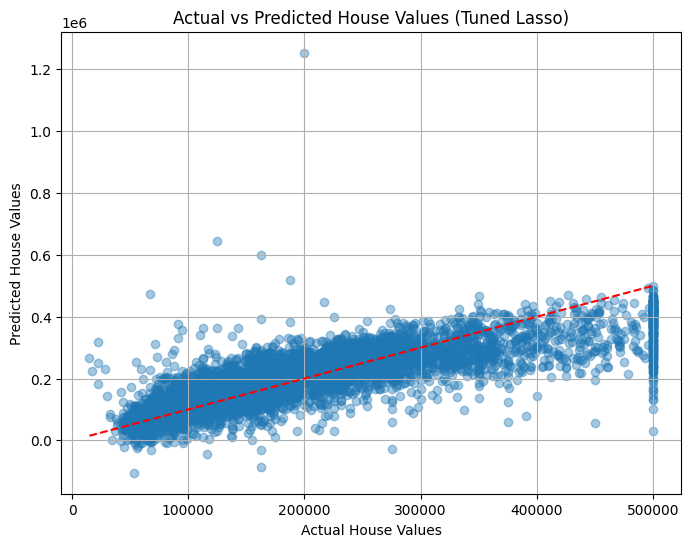

In [51]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    lasso_tuned_predictions,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values (Tuned Lasso)")
plt.grid(True)
plt.show()

### Residual Distribution Plot

Residuals represent the difference between actual and predicted house prices. This plot helps analyze the distribution of prediction errors and identify whether the model systematically overestimates or underestimates house prices.

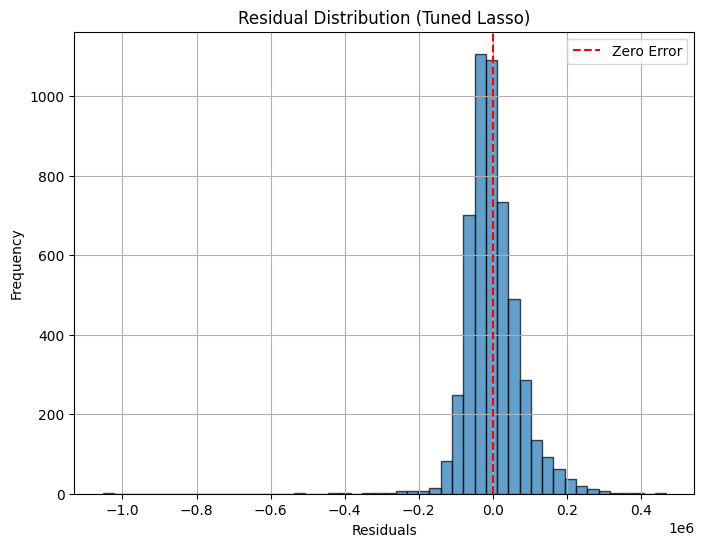

In [52]:
residuals = y_test - lasso_tuned_predictions

plt.figure(figsize=(8, 6))

plt.hist(residuals, bins=50, edgecolor='black', alpha=0.7)

plt.axvline(0, color='red', linestyle='--', label='Zero Error')

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution (Tuned Lasso)")
plt.legend()
plt.grid(True)
plt.show()

## Conclusion

In this project, California Housing data was analyzed to predict median house values using OLS, Ridge, and Lasso Regression.

Data preprocessing, missing value treatment, feature engineering, correlation analysis, and multicollinearity handling were performed before model training. Ridge and Lasso Regression were further optimized using GridSearchCV with five-fold cross-validation.

Among the three evaluated models, Tuned Lasso Regression achieved the best performance with an RMSE of 71,950.95, MAE of 51,469.68, and R² score of 0.6088, using an optimal alpha value of 100.

The results indicate that the model explains approximately 60.88% of the variation in median house values. Although Tuned Lasso performed best among the tested models, there is still room for improvement in prediction accuracy.

Overall, this project demonstrates the application of regression techniques, regularization, hyperparameter tuning, and model evaluation for real-world housing price prediction.